In [5]:
!pip install -q datasets==4.3.0
!pip install -q trl==0.24.0
!pip install -q unsloth
!pip install -q peft accelerate bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.3/199.3 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 12.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.9.0 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 11.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.4/82.4 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.7/29.7 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 7.7 MB/s eta 0:00:00
   ━━━━━

In [1]:
import torch
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), "| VRAM:", round(torch.cuda.get_device_properties(0).total_memory/1024**3, 2), "GB")
else:
    print("No GPU. Runtime > Change runtime type > T4 GPU")

PyTorch: 2.11.0+cu130 | CUDA: True
GPU: Tesla T4 | VRAM: 14.56 GB


In [2]:
import json, random, re, csv, time, subprocess, sys, zipfile, shutil, collections
from pathlib import Path
from PIL import Image
import pandas as pd

# Paths. Change SRC if your copy of the task files is somewhere else.
# SRC must contain: development-*.zip, test-*.zip, sequences.json, sample_submission.jsonl, score.py
try:
    from google.colab import drive
    drive.mount('/content/drive')
    SRC = Path('/content/drive/MyDrive/manga_task')
    DATA = Path('/content/data')
except ImportError:
    SRC = Path('manga_task')
    DATA = Path('data')
OUT = SRC / 'outputs'
OUT.mkdir(parents=True, exist_ok=True)
DATA.mkdir(exist_ok=True)


def write_jsonl(path, items):
    with open(path, 'w', encoding='utf-8') as f:
        for item in items:
            f.write(json.dumps(item, ensure_ascii=False) + '\n')


# unzip the dataset once
if not (DATA / 'development' / 'labels.jsonl').exists():
    for pattern in ['development-*.zip', 'test-*.zip']:
        files = list(SRC.glob(pattern))
        assert files, f'no file matching {pattern} in {SRC}'
        with zipfile.ZipFile(files[0]) as z:
            z.extractall(DATA)
    for name in ['sequences.json', 'sample_submission.jsonl', 'score.py']:
        shutil.copy(SRC / name, DATA / name)

seqs = json.load(open(DATA / 'sequences.json'))
rows = [json.loads(l) for l in open(DATA / 'development' / 'labels.jsonl') if l.strip()]
labels = {r['sequence_id']: r['pages'] for r in rows}
test_ids = [json.loads(l)['sequence_id'] for l in open(DATA / 'sample_submission.jsonl') if l.strip()]
seq_by_id = {s['sequence_id']: s for s in seqs}

# Train/validation split by sequence, seed 42. Same result every run, so this
# notebook does not need the earlier notebook to have created split.json.
SEED, VAL_FRAC = 42, 0.2
ids = sorted(labels)
random.Random(SEED).shuffle(ids)
n_val = round(len(ids) * VAL_FRAC)
val_ids, train_ids = sorted(ids[:n_val]), sorted(ids[n_val:])
assert not set(train_ids) & set(val_ids), 'overlap between train and val'

split_file = OUT / 'split.json'
if split_file.exists():
    saved = json.load(open(split_file))
    assert saved['train'] == train_ids and saved['val'] == val_ids, 'saved split.json differs from the seed-42 split'
else:
    json.dump({'seed': SEED, 'train': train_ids, 'val': val_ids}, open(split_file, 'w'), indent=2)

# score.py needs a reference file containing exactly the sequences being scored
row_by_id = {r['sequence_id']: r for r in rows}
write_jsonl(OUT / 'train_labels.jsonl', [row_by_id[i] for i in train_ids])
write_jsonl(OUT / 'val_labels.jsonl', [row_by_id[i] for i in val_ids])
print(len(labels), 'labelled |', len(train_ids), 'train |', len(val_ids), 'val |', len(test_ids), 'test')

Mounted at /content/drive
80 labelled | 64 train | 16 val | 15 test


In [ ]:
def write_jsonl(path, items):
    with open(path, 'w', encoding='utf-8') as f:
        for item in items:
            f.write(json.dumps(item, ensure_ascii=False) + '\n')

def run_scorer(refs, preds, out_json):
    r = subprocess.run([sys.executable, str(DATA / 'score.py'), '--references', str(refs),
                        '--predictions', str(preds), '--output', str(out_json)],
                       capture_output=True, text=True)
    print(r.stdout or r.stderr)

def norm(t):
    return re.sub(r'\s+', ' ', t.strip().lower())

def dedupe_page(page):
    seen, out = set(), []
    for line in page:
        k = norm(line['text'])
        if k in seen:
            continue
        seen.add(k)
        out.append(line)
    return out

def log_experiment(exp, pipeline, training, score_path, notes=''):
    m = json.load(open(score_path))['macro']
    log = OUT / 'experiments.csv'
    is_new = not log.exists()
    fmt = lambda v: '' if v is None else round(v, 4)
    with open(log, 'a', newline='', encoding='utf-8') as f:
        w = csv.writer(f)
        if is_new:
            w.writerow(['experiment','pipeline','training','text_order','joint_f1','balanced_joint_f1','speaker_acc_matched','coverage','notes'])
        w.writerow([exp, pipeline, training, fmt(m['text_order_score']), fmt(m['joint_f1']), fmt(m['balanced_joint_f1']),
                    fmt(m['speaker_accuracy_on_matched']), fmt(m['matched_token_coverage']), notes])

In [12]:
PROMPT_D = """You are transcribing three consecutive pages of an English manga. The pages are given in reading order as Page 1, Page 2, Page 3. Extract ONLY the story text of each page and answer with JSON.

INCLUDE: speech and thought balloons, narration boxes (plain rectangular caption boxes), clear spoken screams or grunts, balloons that contain only punctuation such as "..." or "?!".
EXCLUDE: sound effects, translator or editor notes, decorative taglines or titles, "last time" recap boxes, page numbers, credits, logos, ads, text on signs, clothes, objects or screens.

ORDER: manga is read right-to-left, top-to-bottom. One balloon = one line. In a balloon with several vertical columns, read the rightmost column first.

SPEAKERS: label each line with the speaker. Number characters character1, character2, ... in order of first appearance ACROSS ALL THREE PAGES. The same person keeps the same label on every page. Use NARRATION only for rectangular narration boxes. Use UNKNOWN if the speaker is off-panel or unclear.

Do not repeat any line. A page with no story text is an empty list.

OUTPUT only JSON, exactly in this form:
{"pages": [[{"speaker": "character1", "text": "..."}], [], [{"speaker": "character2", "text": "..."}]]}"""

def relabel_sequence(pages):
    # character labels -> character1, character2, ... by first appearance over the WHOLE sequence
    names, result = {}, []
    for page in pages:
        new_page = []
        for line in page:
            sp = line['speaker']
            if sp not in ('NARRATION', 'UNKNOWN'):
                if sp not in names:
                    names[sp] = f'character{len(names) + 1}'
                sp = names[sp]
            new_page.append({'speaker': sp, 'text': line['text']})
        result.append(new_page)
    return result

def _clean_page(page):
    if isinstance(page, dict):
        page = page.get('lines', [])
    out = []
    if not isinstance(page, list):
        return out
    for it in page:
        if isinstance(it, dict) and isinstance(it.get('speaker'), str) and isinstance(it.get('text'), str):
            s, t = it['speaker'].strip(), it['text'].strip()
            if s and t:
                out.append({'speaker': s, 'text': t})
    return out

def parse_sequence_output(raw):
    """Returns (pages, status). status is 'ok', 'repaired' or 'failed'. Always exactly 3 pages."""
    raw = raw.replace('```json', '').replace('```', '')
    start = raw.find('{')
    if start < 0:
        return [[], [], []], 'failed'
    body = raw[start:]
    cut = body[:body.rfind('}') + 1]
    for status_i, suffix in enumerate(['', ']]}', ']}', '}']):
        try:
            data = json.loads(cut + suffix)
            pages = data['pages'] if isinstance(data, dict) else None
            if not isinstance(pages, list):
                continue
            pages = [_clean_page(p) for p in pages][:3]
            while len(pages) < 3:
                pages.append([])
            return pages, ('ok' if status_i == 0 else 'repaired')
        except (ValueError, KeyError, TypeError):
            continue
    return [[], [], []], 'failed'

# CPU self-tests
p, s = parse_sequence_output('{"pages": [[{"speaker":"character1","text":"Hi"}],[],[]]}')
assert s == 'ok' and len(p) == 3 and p[0][0]['text'] == 'Hi'
p, s = parse_sequence_output('```json\n{"pages": [[{"speaker":"character1","text":"Hi"}],[{"speaker":"character2","text":"Yo"}],[]]}\n```')
assert s == 'ok' and p[1][0]['speaker'] == 'character2'
p, s = parse_sequence_output('{"pages": [[{"speaker":"character1","text":"Hi"}],[{"speaker":"character2","text":"Yo"},{"speaker":"character1","text":"Cut off here')
assert s == 'repaired' and len(p) == 3 and p[1][0]['text'] == 'Yo' and p[2] == []
p, s = parse_sequence_output('no json at all')
assert s == 'failed' and p == [[], [], []]
r = relabel_sequence([[{'speaker':'bob','text':'a'},{'speaker':'NARRATION','text':'b'}],[{'speaker':'amy','text':'c'},{'speaker':'bob','text':'d'}],[]])
assert [l['speaker'] for l in r[0]+r[1]] == ['character1','NARRATION','character2','character1']
print('parser and relabel tests passed')

parser and relabel tests passed


In [13]:
MAX_SIDE = 768

def prepare_image(path):
    img = Image.open(path).convert('RGB')
    scale = MAX_SIDE / max(img.size)
    if scale < 1:
        img = img.resize((round(img.width * scale), round(img.height * scale)), Image.LANCZOS)
    return img

def build_content(images, prompt):
    content = []
    for n, img in enumerate(images, 1):
        content.append({'type': 'text', 'text': f'Page {n}:'})
        content.append({'type': 'image', 'image': img})
    content.append({'type': 'text', 'text': prompt})
    return content

def run_vlm_seq(images, prompt, max_new_tokens=2048):
    messages = [{'role': 'user', 'content': [
        *[x for n in range(len(images)) for x in ({'type': 'text', 'text': f'Page {n+1}:'}, {'type': 'image'})],
        {'type': 'text', 'text': prompt}]}]
    text = tokenizer.apply_chat_template(messages, add_generation_prompt=True)
    inputs = tokenizer(images, text, add_special_tokens=False, return_tensors='pt').to('cuda')
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, use_cache=True)
    return tokenizer.batch_decode(out[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True)[0]

def process_sequence_d(seq, prompt=PROMPT_D):
    images = [prepare_image(DATA / rel) for rel in seq['images']]
    raw = run_vlm_seq(images, prompt)
    pages, status = parse_sequence_output(raw)
    return pages, raw, status

In [ ]:
#loading base model
from unsloth import FastVisionModel

model, tokenizer = FastVisionModel.from_pretrained(
    "unsloth/Qwen2-VL-7B-Instruct",
    load_in_4bit=True,
    use_gradient_checkpointing="unsloth",
)
print("VRAM (GB):", round(torch.cuda.memory_allocated() / 1024**3, 2))

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.3: Fast Qwen2_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/730 [00:00<?, ?it/s]

VRAM (GB): 6.39


In [ ]:
#train sequence level lora
def make_example_d(seq_id):
    seq = seq_by_id[seq_id]
    images = [prepare_image(DATA / rel) for rel in seq['images']]
    answer = json.dumps({'pages': relabel_sequence(labels[seq_id])}, ensure_ascii=False)
    return {'messages': [
        {'role': 'user', 'content': build_content(images, PROMPT_D)},
        {'role': 'assistant', 'content': [{'type': 'text', 'text': answer}]},
    ]}

train_data = [make_example_d(sid) for sid in train_ids]
print('training examples (sequences):', len(train_data))
print(train_data[0]['messages'][1]['content'][0]['text'][:300])

training examples (sequences): 64
{"pages": [[{"speaker": "character1", "text": "I MEAN..."}, {"speaker": "character1", "text": "YOU'RE THE ONLY ONE"}, {"speaker": "character1", "text": "WHO'S EVER SEEN ME LIKE THIS."}, {"speaker": "character2", "text": "TH..."}, {"speaker": "character2", "text": "THE ONLY ONE...?"}, {"speaker": "ch


In [ ]:
model = FastVisionModel.get_peft_model(
    model,
    finetune_vision_layers=False,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,
    r=16, lora_alpha=16, lora_dropout=0, bias="none", random_state=3407,
)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f'Trainable: {trainable:,} of {total:,} ({100*trainable/total:.2f}%)  (model C had 40,370,176)')

Trainable: 40,370,176 of 5,052,717,568 (0.80%)  (model C had 40,370,176)


In [ ]:
from unsloth import is_bf16_supported
from unsloth.trainer import UnslothVisionDataCollator

# the collator cuts every example at a maximum length (2048 by default). Our examples are longer, so raise it.
collator_args = dict(
    resize="max",
    train_on_responses_only=True,
    instruction_part="<|im_start|>user\n",
    response_part="<|im_start|>assistant\n",
)
try:
    collator = UnslothVisionDataCollator(model, tokenizer, max_seq_length=4096, **collator_args)
except TypeError:
    print('this Unsloth version has no max_seq_length argument; setting it on the model instead')
    model.max_seq_length = 4096
    collator = UnslothVisionDataCollator(model, tokenizer, **collator_args)
batch = collator([train_data[0]])
ids, lab = batch['input_ids'][0], batch['labels'][0]
print('total tokens:', ids.shape[0])
print('tokens counted in loss:', int((lab != -100).sum()))
print('image_grid_thw (one row per image: t, h, w in 14px patches):')
print(batch['image_grid_thw'])
g = batch['image_grid_thw']
print('image tokens per image (grid/4):', [int(r.prod()) // 4 for r in g])
print('loss text starts with:', repr(tokenizer.decode(ids[lab != -100][:25])))
print('loss text ends with  :', repr(tokenizer.decode(ids[lab != -100][-12:])))
tail = tokenizer.decode(ids[lab != -100][-12:])
print('LONGEST example check (worst case for length):')
lens = []
for ex in train_data[:8]:
    b = collator([ex]); lens.append(int(b['input_ids'].shape[1]))
print('token lengths of 8 examples:', lens)
assert max(lens) != 2048, 'STILL CUT AT 2048: the length limit was not raised'
assert tail.strip().endswith(']}') or tail.strip().endswith('<|im_end|>') or ']]}' in tail, 'answer does not end with ]]} : it is still being cut'
print('OK: answers are complete')

total tokens: 2351
tokens counted in loss: 575
image_grid_thw (one row per image: t, h, w in 14px patches):
tensor([[ 1, 54, 36],
        [ 1, 54, 36],
        [ 1, 54, 36]])
image tokens per image (grid/4): [486, 486, 486]
loss text starts with: '{"pages": [[{"speaker": "character1", "text": "I MEAN..."}, {"speaker": "character'
loss text ends with  : ' NOT SO SCARY, IS IT?"}]]}<|im_end|>'
LONGEST example check (worst case for length):
token lengths of 8 examples: [2351, 2417, 2157, 2660, 2473, 2219, 2453, 2131]
OK: answers are complete


In [ ]:
from trl import SFTTrainer, SFTConfig

FastVisionModel.for_training(model)
CKPT = OUT / 'checkpoints_d'

trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    data_collator=collator,
    train_dataset=train_data,
    args=SFTConfig(
        per_device_train_batch_size=1,
        gradient_accumulation_steps=4,
        num_train_epochs=4,
        learning_rate=1e-4,
        warmup_steps=5,
        weight_decay=0.01,
        lr_scheduler_type="linear",
        optim="adamw_8bit",
        fp16=not is_bf16_supported(),
        bf16=is_bf16_supported(),
        logging_steps=1,
        save_steps=16,
        save_total_limit=2,
        output_dir=str(CKPT),
        report_to="none",
        seed=3407,
        remove_unused_columns=False,
        dataset_text_field="",
        dataset_kwargs={"skip_prepare_dataset": True},
        max_length=4096,
    ),
)
has_checkpoint = CKPT.exists() and any(CKPT.glob('checkpoint-*'))
torch.cuda.reset_peak_memory_stats()
trainer.train(resume_from_checkpoint=has_checkpoint)
print('peak VRAM (GB):', round(torch.cuda.max_memory_allocated() / 1024**3, 2))

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 64 | Num Epochs = 4 | Total steps = 64
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 4 x 1) = 4
 "-____-"     Trainable parameters = 40,370,176 of 8,331,745,792 (0.48% trained)


Step,Training Loss


peak VRAM (GB): 6.7


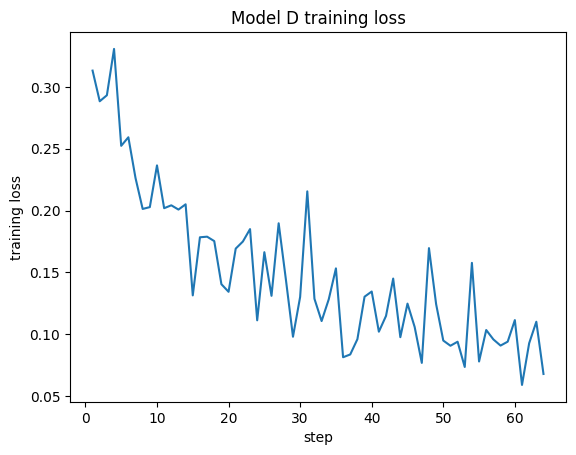

Note: loss now covers the answer only, so it is NOT comparable with the loss curve of model C.


In [ ]:
import matplotlib.pyplot as plt
history = [h for h in trainer.state.log_history if 'loss' in h]
plt.plot([h['step'] for h in history], [h['loss'] for h in history])
plt.xlabel('step'); plt.ylabel('training loss'); plt.title('Model D training loss'); plt.show()
print('Note: loss now covers the answer only, so it is NOT comparable with the loss curve of model C.')

In [ ]:
ADAPTER = OUT / 'lora_adapter_d'
model.save_pretrained(str(ADAPTER))
tokenizer.save_pretrained(str(ADAPTER))
print('saved to', ADAPTER)

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/manga_task/outputs/lora_adapter_d/tokenizer_config.json.


saved to /content/drive/MyDrive/manga_task/outputs/lora_adapter_d


In [6]:
from unsloth import FastVisionModel
model, tokenizer = FastVisionModel.from_pretrained(
    '/content/drive/MyDrive/manga_task/outputs/lora_adapter_d',
    load_in_4bit=True,
)
print('adapter loaded')

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


<frozen importlib.util>:91: UserWarning: You are importing from 'trl.experimental'. APIs here are unstable and may change or be removed without notice. Silence this warning by setting environment variable TRL_EXPERIMENTAL_SILENCE=1.


==((====))==  Unsloth 2026.10.4: Fast Qwen2_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/730 [00:00<?, ?it/s]

adapter loaded


In [ ]:
def run_experiment_d(exp, training, notes=''):
    pred_path = OUT / f'{exp}_predictions.jsonl'
    raw_path = OUT / f'{exp}_raw.jsonl'
    (OUT / 'prompts').mkdir(exist_ok=True)
    (OUT / 'prompts' / f'{exp}.txt').write_text(PROMPT_D, encoding='utf-8')

    done = set()
    if pred_path.exists():
        done = {json.loads(l)['sequence_id'] for l in open(pred_path) if l.strip()}
    todo = [s for s in val_ids if s not in done]
    print(f'{exp}: {len(done)} done, {len(todo)} to do')

    start = time.time()
    for n, sid in enumerate(todo, 1):
        try:
            pages, raw, status = process_sequence_d(seq_by_id[sid])
        except Exception as e:
            print('FAILED', sid, e); torch.cuda.empty_cache(); continue
        with open(pred_path, 'a', encoding='utf-8') as f:
            f.write(json.dumps({'sequence_id': sid, 'pages': pages}, ensure_ascii=False) + '\n')
        with open(raw_path, 'a', encoding='utf-8') as f:
            f.write(json.dumps({'sequence_id': sid, 'raw': raw, 'parse_status': status}, ensure_ascii=False) + '\n')
        print(f'[{n}/{len(todo)}] {sid} lines={[len(p) for p in pages]} parse={status} ({(time.time()-start)/60:.1f} min)')

    score_path = OUT / f'{exp}_scores.json'
    run_scorer(OUT / 'val_labels.jsonl', pred_path, score_path)
    log_experiment(exp, 'sequence-level: 3 pages per call, sequence-wide labels', training, score_path, notes)

FastVisionModel.for_inference(model)
run_experiment_d('D_sequence_lora',
                 'LoRA r16, 64 train sequences, 4 epochs, answer-only loss, 768px',
                 notes='several changes vs C at once (3 pages, seq labels, 768px, answer-only loss, 4 epochs)')

D_sequence_lora: 16 done, 0 to do
{
  "text_order_score": 0.7517245708148816,
  "balanced_joint_f1": 0.2880748921429838,
  "speaker_accuracy_on_matched": 0.6194470308371133,
  "joint_f1": 0.4977843159546488,
  "matched_token_coverage": 0.8250376451278016
}



In [ ]:
stat = collections.Counter(json.loads(l).get('parse_status') for l in open(OUT / 'D_sequence_lora_raw.jsonl'))
print('parse status counts:', dict(stat), '  (ideal: all ok; failed means the model output could not be read at all)')

preds = [json.loads(l) for l in open(OUT / 'D_sequence_lora_predictions.jsonl')]
dd = [{'sequence_id': r['sequence_id'], 'pages': [dedupe_page(p) for p in r['pages']]} for r in preds]
write_jsonl(OUT / 'D_sequence_lora_dedupe_predictions.jsonl', dd)
run_scorer(OUT / 'val_labels.jsonl', OUT / 'D_sequence_lora_dedupe_predictions.jsonl', OUT / 'D_sequence_lora_dedupe_scores.json')
done_logged = 'D_sequence_lora_dedupe' in set(pd.read_csv(OUT / 'experiments.csv')['experiment'])
if not done_logged:
    log_experiment('D_sequence_lora_dedupe', 'D + dedupe repeated lines per page', 'as D', OUT / 'D_sequence_lora_dedupe_scores.json')

parse status counts: {'repaired': 1, 'ok': 15}   (ideal: all ok; failed means the model output could not be read at all)
{
  "text_order_score": 0.760665713731746,
  "balanced_joint_f1": 0.31420145176926956,
  "speaker_accuracy_on_matched": 0.6213637196195099,
  "joint_f1": 0.515714986482367,
  "matched_token_coverage": 0.8214269627335199
}



In [ ]:
#comparing c and D
df = pd.read_csv(OUT / 'experiments.csv').drop_duplicates(subset='experiment', keep='last')
show = df[df['experiment'].str.contains('C_lora|D_sequence')]
display(show.drop(columns=['pipeline', 'training', 'notes']))

,experiment,text_order,joint_f1,balanced_joint_f1,speaker_acc_matched,coverage
4,C_lora_v2prompt,0.6047,0.4259,0.2467,0.5972,0.7275
5,C_lora_v2prompt_keep1,0.6130,0.4305,0.2504,0.5956,0.7149
9,D_sequence_lora_dedupe,0.7607,0.5157,0.3142,0.6214,0.8214
10,D_sequence_lora,0.7517,0.4978,0.2881,0.6194,0.8250


In [ ]:
import tempfile, os
def per_seq(pred_file):
    preds = {json.loads(l)['sequence_id']: json.loads(l) for l in open(pred_file)}
    refs = {r['sequence_id']: r for r in rows}
    res = {}
    for sid in val_ids:
        with tempfile.TemporaryDirectory() as d:
            write_jsonl(f'{d}/r.jsonl', [refs[sid]])
            write_jsonl(f'{d}/p.jsonl', [preds[sid]])
            subprocess.run([sys.executable, str(DATA/'score.py'), '--references', f'{d}/r.jsonl',
                            '--predictions', f'{d}/p.jsonl', '--output', f'{d}/o.json'], capture_output=True)
            res[sid] = json.load(open(f'{d}/o.json'))['macro']['joint_f1']
    return res

c = per_seq(OUT / 'C_lora_v2prompt_keep1_predictions.jsonl')
d = per_seq(OUT / 'D_sequence_lora_dedupe_predictions.jsonl')
better = sum(1 for s in val_ids if d[s] > c[s])
print(f'D+dedupe beats C+dedupe on {better} of {len(val_ids)} sequences (joint_f1)')
for s in val_ids:
    print(s, round(c[s], 3), round(d[s], 3))

D+dedupe beats C+dedupe on 13 of 16 sequences (joint_f1)
seq_2032620aa4e4ac7f 0.511 0.552
seq_45c9871f52e99417 0.58 0.778
seq_5f9ee35846b7e635 0.446 0.472
seq_84541a1f4b159018 0.376 0.421
seq_952f154fb1505883 0.276 0.196
seq_96839890d69d7698 0.648 0.754
seq_a3bd36201a0cd61b 0.028 0.024
seq_b136f32c2233b97c 0.519 0.468
seq_b8b5563330fdc89d 0.213 0.361
seq_b9b5a9ad9a64ced9 0.531 0.565
seq_d749b853cf795b6a 0.322 0.646
seq_d8afceb0e8f9122d 0.651 0.778
seq_da71f7a842c91090 0.334 0.562
seq_de542b63e6b19bc2 0.521 0.559
seq_e8b4f75454f9491f 0.59 0.656
seq_f7f9d9dbf5b05cb5 0.342 0.458


 test predictions with D


In [8]:
def predict_test(pred_path, raw_path, use_dedupe=True):
    FastVisionModel.for_inference(model)
    done = set()
    if pred_path.exists():
        done = {json.loads(l)['sequence_id'] for l in open(pred_path) if l.strip()}
    for sid in test_ids:
        if sid in done:
            continue
        pages, raw, status = process_sequence_d(seq_by_id[sid])
        kept = [dedupe_page(p) for p in pages] if use_dedupe else pages
        with open(raw_path, 'a', encoding='utf-8') as f:      # raw first, so a crash never leaves a prediction without its raw text
            f.write(json.dumps({'sequence_id': sid, 'raw': raw, 'parse_status': status}, ensure_ascii=False) + '\n')
        with open(pred_path, 'a', encoding='utf-8') as f:
            f.write(json.dumps({'sequence_id': sid, 'pages': kept}, ensure_ascii=False) + '\n')
        print(sid, [len(p) for p in kept], status)
    print('sequences written:', sum(1 for _ in open(pred_path)))
    if raw_path.exists():
        print('parse status:', dict(collections.Counter(json.loads(l)['parse_status'] for l in open(raw_path))))


USE_DEDUPE = True
FINAL = OUT / 'final_predictions_d.jsonl'
FINAL_RAW = OUT / 'final_predictions_d_raw.jsonl'
predict_test(FINAL, FINAL_RAW, USE_DEDUPE)

sequences written: 15


In [9]:
def validate_predictions(path, expected_ids):
    seen = []
    for n, line in enumerate(open(path, encoding='utf-8'), 1):
        row = json.loads(line)
        assert set(row) == {'sequence_id', 'pages'}, f'line {n}: extra or missing keys'
        assert isinstance(row['pages'], list) and len(row['pages']) == 3, f'line {n}: need exactly 3 pages'
        for page in row['pages']:
            assert isinstance(page, list), f'line {n}: a page is not a list'
            for item in page:
                assert set(item) == {'speaker', 'text'}, f'line {n}: bad item keys'
                assert isinstance(item['speaker'], str) and item['speaker'].strip(), f'line {n}: empty speaker'
                assert isinstance(item['text'], str) and item['text'].strip(), f'line {n}: empty text'
        seen.append(row['sequence_id'])
    assert sorted(seen) == sorted(expected_ids), 'sequence ids do not match the expected ids'
    assert len(seen) == len(set(seen)), 'duplicate sequence ids'
    print('OK:', len(seen), 'sequences')

validate_predictions(OUT / 'final_predictions_d.jsonl', test_ids)

OK: 15 sequences


In [14]:
# requirements for model D
import platform, importlib.metadata as md_

packages = ['torch', 'transformers', 'unsloth', 'unsloth_zoo', 'peft', 'trl', 'accelerate', 'bitsandbytes', 'datasets', 'pillow']
lines = []
for p in packages:
    try:
        lines.append(f'{p}=={md_.version(p)}')
    except Exception:
        lines.append(f'# {p} not found')
(OUT / 'requirements_d.txt').write_text('\n'.join(lines) + '\n')

info = {
    'python': platform.python_version(),
    'gpu': torch.cuda.get_device_name(0),
    'base_model': 'unsloth/Qwen2-VL-7B-Instruct (4-bit)',
    'split_seed': SEED,
    'image_max_side': MAX_SIDE,
    'lora': {'r': 16, 'alpha': 16, 'dropout': 0, 'vision_layers': False, 'language_layers': True},
    'training': {'batch_size': 1, 'grad_accum': 4, 'epochs': 4, 'lr': 1e-4, 'loss': 'answer only', 'max_seq_length': 4096, 'seed': 3407},
    'inference': {'do_sample': False, 'max_new_tokens': 2048},
    'postprocessing': 'drop repeated lines on a page (case and spacing ignored)' if USE_DEDUPE else 'none',
}
json.dump(info, open(OUT / 'run_info_d.json', 'w'), indent=2)
print(open(OUT / 'requirements_d.txt').read())

torch==2.11.0+cu130
transformers==5.17.0
unsloth==2026.10.4
unsloth_zoo==2026.10.4
peft==0.21.1
trl==0.24.0
accelerate==1.15.0
bitsandbytes==0.50.2
datasets==4.3.0
pillow==11.3.0

